<a href="https://colab.research.google.com/github/BuvanAlfarezy/BuvanAlfarezy_Test_AnalisisSentimen/blob/main/Praktikum3_AnalisisSentimen_Ruangguru_NaiveBayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install google-play-scraper scikit-learn imbalanced-learn Sastrawi wordcloud seaborn matplotlib pandas numpy joblib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 209.7/209.7 kB 5.0 MB/s eta 0:00:00


In [2]:
%%writefile app.py
import streamlit as st
import pandas as pd
import numpy as np
import pickle

st.set_page_config(
    page_title="Prediksi Survival Titanic",
    page_icon="👋",
    layout="centered"
)

@st.cache_resource
def Load_artifacts():
    with open("model.pkl", "rb") as f:
        model = pickle.load(f)
    with open("scaler.pkl", "rb") as f:
        scaler = pickle.load(f)
    with open("le_sex.pkl", "rb") as f:
        le_sex = pickle.load(f)
    with open("le_embarked.pkl", "rb") as f:
        le_embarked = pickle.load(f)
    return model, scaler, le_sex, le_embarked

try:
    model, scaler, le_sex, le_embarked = Load_artifacts()
    artifacts_loaded = True
except (FileNotFoundError, EOFError, pickle.UnpicklingError):
    artifacts_loaded = False

# Header
st.title("Prediksi Survival Titanic")
st.markdown(
    """
    Aplikasi in memprediksi **peluang seorang penumpang akan selamat** dalamP tragedi Titanic, menggunakan model **Random Forest Classifier**
    yang telah dilatih pada dataset Titanic.
    """
)

if not artifacts_loaded:
  st.error(
      "File model (model.pkl/ scaler.pkl / le_sex.pkl / le_embarked.pkl)"
      "tidak ditemukan. Jalankan dulu notebook 'Klasifikasi_Titanic.ipynb'"
      "sampai selesai supaya file-file tersebut dibuat, lalu taruh di folder yang sama dengan app.py"
  )
  st.stop()

st.divider()

# Form Input Data Penumpang
st.subheader("Masukkan Data Penumpang")

col1, col2 = st.columns(2)

with col1:
    pclass = st.selectbox(
        "Kelas Tiket (Pclass)",
        options=[1, 2, 3],
        index=2,
        help="1 = Kelas 1 (mewah), 2 = Kelas 2, 3 = Kelas 3 (ekonomi)"
    )
    sex = st.radio("Jenis Kelamin", options=["male", "female"], horizontal=True)
    age = st.slider("Umur", min_value=0, max_value=100, value=30)
    fare = st.number_input("Harga Tiket (Fare)", min_value=0.0, max_value=600.0, value=32.0, step=1.0)

with col2:
    sibsp = st.number_input("Jumlah Saudara/Pasangan di Kapal (SibSp)", min_value=0, max_value=10, value=0)
    parch = st.number_input("Jumlah Orang Tua/Anak di Kapal (Parch)", min_value=0, max_value=10, value=0)
    embarked = st.selectbox(
        "Pelabuhan Keberangkatan (Embarked)",
        options=["S", "C", "Q"],
        help="S = Southampton, C = Cherbourg, Q = Queenstown"
    )

family_size = sibsp + parch + 1
st.caption(f"Total anggota keluarga di kapal (FamilySize): **{family_size}**")


st.divider()

if st.button("Prediksi Sekarang", type="primary", use_container_width=True):

    sex_encoded = le_sex.transform([sex])[0]
    embarked_encoded = le_embarked.transform([embarked])[0]

    # PERBAIKAN: Hanya 7 fitur yang sesuai saat melatih model
    input_data = pd.DataFrame([{
        "Pclass": pclass,
        "Sex": sex_encoded,
        "Age": age,
        "SibSp": sibsp,
        "Parch": parch,
        "Fare": fare,
        "Embarked": embarked_encoded
    }])

  # Scaling
    input_scaled = scaler.transform(input_data)

    # Prediksi
    prediction = model.predict(input_scaled)[0]
    probability = model.predict_proba(input_scaled)[0]

    st.subheader("Hasil Prediksi")

    if prediction == 1:
        st.success(f"**SELAMAT** - Peluang selamat: {probability[1]*100:.2f}%")
    else:
        st.error(f"**TIDAK SELAMAT** - Peluang tidak selamat: {probability[0]*100:.2f}%")

    # Tampilkan grafik probabilitas
    prob_df = pd.DataFrame({
        "Status": ["Tidak Selamat", "Selamat"],
        "Probabilitas (%)": [probability[0] * 100, probability[1] * 100]
    })
    st.bar_chart(prob_df.set_index("Status"))

    with st.expander("Lihat data input yang digunakan model"):
        st.dataframe(input_data)

st.divider()
st.caption(
    "Model: Random Forest Classifier • Dataset: Titanic (891 penumpang) • "
    "Dibuat dengan Streamlit"
)

Writing app.py


In [3]:
from google_play_scraper import Sort, reviews
import pandas as pd
import numpy as np

#1 Step 1: Scraping ulasan aplikasi Ruangguru
result, continuation_token = reviews(
    'com.ruangguru.livestudents',
    lang='id',
    country='id',
    sort=Sort.MOST_RELEVANT,
    count=1000,
    filter_score_with=None
)

df_reviews = pd.DataFrame(result)

new_df = df_reviews[['userName', 'score', 'at', 'content']]

sorted_df = new_df.sort_values(by='at', ascending=False)

my_df = sorted_df[['userName', 'score', 'at', 'content']]
my_df.to_csv('scrapped_data.csv', index=False)

print("Jumlah ulasan:", len(my_df))
print("Data Berhasil disimpan ke file CSV.")
display(my_df.head())

Jumlah ulasan: 1000
Data Berhasil disimpan ke file CSV.


,userName,score,at,content
33,Kenosis Miracle yani,5,2026-10-19 02:04:59,aplikasinya sangat interaktif dan membantu say...
92,Nurafni Lala,5,2026-10-17 09:36:49,bagus dan bisa memperlancar anak pintar dan be...
43,Top up robux,5,2026-10-17 09:23:56,the best bagus bener dan juga mudah untuk nger...
35,Rokayah,5,2026-10-16 14:14:38,"belajar jadi lebih mudah,asik,seru dan menyena..."
34,Altaf,5,2026-10-16 05:44:16,ruangguru mantap banget gratis pasti. aku dapa...


In [10]:
import re, json, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_curve, roc_auc_score)
from imblearn.over_sampling import SMOTE, RandomOverSampler
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"Negatif": "#EF4444", "Netral": "#F59E0B", "Positif": "#10B981"}
SEED = 42

In [11]:
SCRAPE = False                  # True = scraping ulang dari Play Store
DATA_PATH = "scrapped_data.csv"  # ubah sesuai lokasi file Anda
APP_ID = "com.ruangguru.livestudents"
N_REVIEWS = 1000

if SCRAPE:
    from google_play_scraper import Sort, reviews
    result, _ = reviews(APP_ID, lang="id", country="id", sort=Sort.MOST_RELEVANT, count=N_REVIEWS)
    df_raw = pd.DataFrame(result)[["userName", "score", "at", "content"]]
    df_raw = df_raw.sort_values("at", ascending=False)
    df_raw.to_csv(DATA_PATH, index=False)
else:
    df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")

# Validasi kolom & buang data kosong
assert {"score", "content"}.issubset(df_raw.columns), "Kolom 'score' dan 'content' wajib ada"
df = df_raw.dropna(subset=["content", "score"]).copy()
df["at"] = pd.to_datetime(df["at"], errors="coerce")
df = df.reset_index(drop=True)
print(f"Data dimuat: {df.shape[0]} baris, {df.shape[1]} kolom")
df.head()

Data dimuat: 1000 baris, 4 kolom


,userName,score,at,content
0,Kenosis Miracle yani,5,2026-10-19 02:04:59,aplikasinya sangat interaktif dan membantu say...
1,Nurafni Lala,5,2026-10-17 09:36:49,bagus dan bisa memperlancar anak pintar dan be...
2,Top up robux,5,2026-10-17 09:23:56,the best bagus bener dan juga mudah untuk nger...
3,Rokayah,5,2026-10-16 14:14:38,"belajar jadi lebih mudah,asik,seru dan menyena..."
4,Altaf,5,2026-10-16 05:44:16,ruangguru mantap banget gratis pasti. aku dapa...


In [12]:
print(df.info())
print("\nMissing value:\n", df.isna().sum())
print(f"\nRentang tanggal: {df['at'].min():%d %b %Y} -> {df['at'].max():%d %b %Y}")
print(f"Ulasan duplikat: {df.duplicated(subset='content').sum()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   userName  1000 non-null   object        
 1   score     1000 non-null   int64         
 2   at        1000 non-null   datetime64[ns]
 3   content   1000 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 31.4+ KB
None

Missing value:
 userName    0
score       0
at          0
content     0
dtype: int64

Rentang tanggal: 15 Sep 2018 -> 19 Oct 2026
Ulasan duplikat: 2


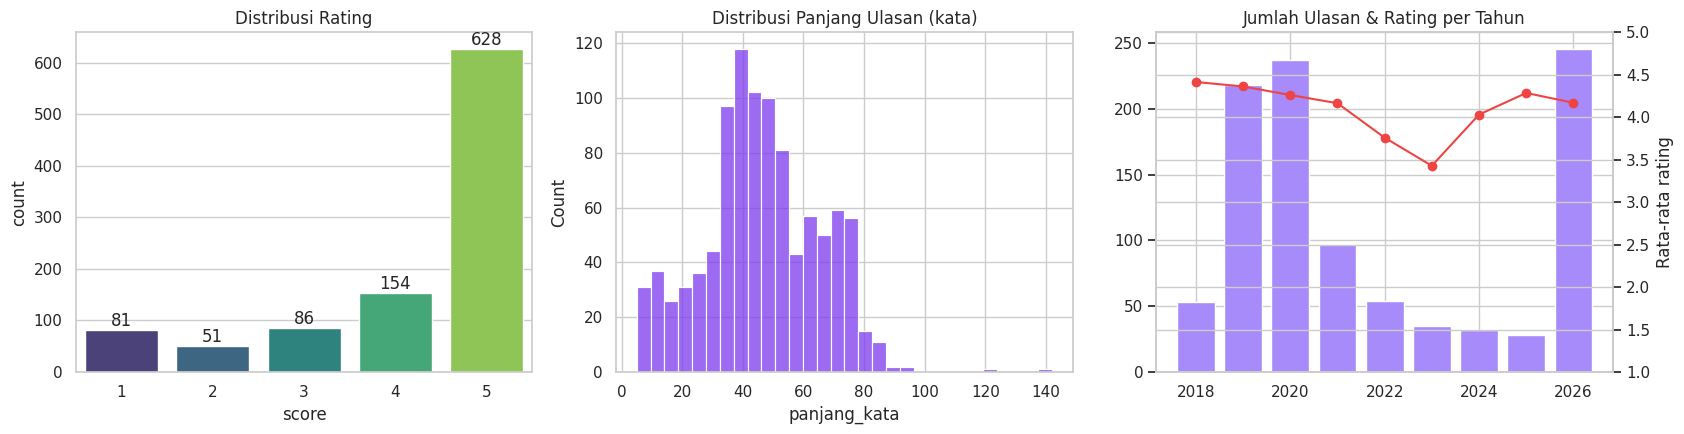

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

sns.countplot(data=df, x="score", palette="viridis", ax=ax[0])
ax[0].set_title("Distribusi Rating")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha="center", va="bottom")

df["panjang_kata"] = df["content"].astype(str).str.split().str.len()
sns.histplot(df["panjang_kata"], bins=30, color="#7C3AED", ax=ax[1])
ax[1].set_title("Distribusi Panjang Ulasan (kata)")

yr = df.dropna(subset=["at"]).groupby(df["at"].dt.year).agg(jumlah=("score", "size"), rating=("score", "mean"))
ax[2].bar(yr.index, yr["jumlah"], color="#A78BFA")
ax2 = ax[2].twinx(); ax2.plot(yr.index, yr["rating"], color="#EF4444", marker="o"); ax2.set_ylim(1, 5); ax2.set_ylabel("Rata-rata rating")
ax[2].set_title("Jumlah Ulasan & Rating per Tahun")
plt.tight_layout(); plt.show()

label
Positif    782
Negatif    132
Netral      86
Name: count, dtype: int64
label
Positif    78.2 %
Negatif    13.2 %
Netral      8.6 %
Name: count, dtype: object


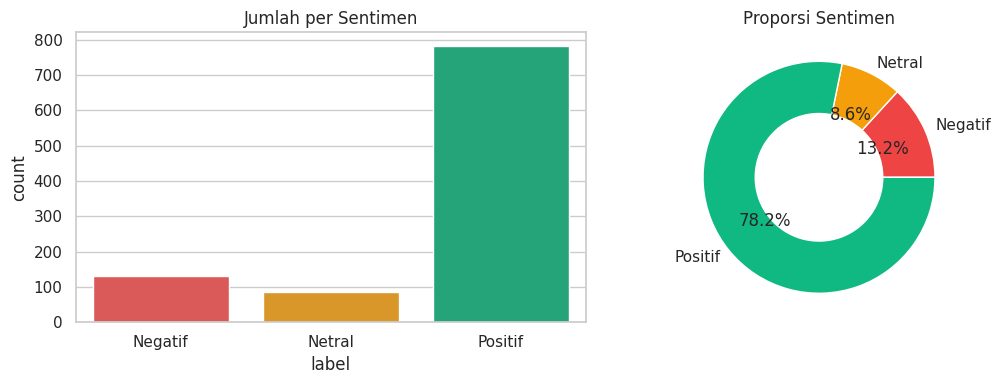

In [14]:
def beri_label(score):
    if score <= 2: return "Negatif"
    if score == 3: return "Netral"
    return "Positif"

df["label"] = df["score"].apply(beri_label)
dist = df["label"].value_counts()
print(dist)
print((dist / dist.sum() * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
order = ["Negatif", "Netral", "Positif"]
sns.countplot(data=df, x="label", order=order, palette=PALETTE, ax=ax[0]); ax[0].set_title("Jumlah per Sentimen")
ax[1].pie(dist[order], labels=order, autopct="%1.1f%%", colors=[PALETTE[o] for o in order], wedgeprops=dict(width=.45))
ax[1].set_title("Proporsi Sentimen"); plt.tight_layout(); plt.show()

In [15]:
STOPWORDS = {
    "di", "dari", "ke", "pada", "dengan", "untuk", "oleh", "tentang", "kepada", "yang", "dan", "atau", "tetapi", "tapi",
    "karena", "meskipun", "jika", "agar", "saya", "aku", "kamu", "dia", "kita", "mereka", "ini", "itu", "lah", "tuh", "nya",
    "dong", "aja", "gitu", "deh", "emang", "ya", "sih", "kok", "lho", "nih", "si", "pun", "juga", "sudah", "akan", "lagi",
    "pernah", "hanya", "adalah", "dalam", "ada", "para", "sebagai", "saat", "ketika", "kalau", "kalo", "jadi", "sama", "mau",
}

NEGATIONS = {"tidak", "bukan", "belum", "jangan", "kurang", "gak", "ga", "nggak", "ngga", "tak", "gk", "enggak"}
DOMAIN_STOPWORDS = {"ruangguru", "rg", "ruang", "kak"}  # nama aplikasi: muncul di hampir semua ulasan

SLANG = {
    "gak": "tidak", "ga": "tidak", "nggak": "tidak", "ngga": "tidak", "gk": "tidak", "enggak": "tidak", "tdk": "tidak", "tak": "tidak",
    "bgt": "banget", "bgus": "bagus", "bagu": "bagus", "bagust": "bagus", "mantul": "mantap", "udh": "sudah", "udah": "sudah",
    "sdh": "sudah", "blm": "belum", "yg": "yang", "dgn": "dengan", "krn": "karena", "karna": "karena", "utk": "untuk", "jd": "jadi",
    "tp": "tapi", "tpi": "tapi", "klo": "kalau", "kalo": "kalau", "sy": "saya", "sm": "sama", "sma": "sama", "bs": "bisa", "bsa": "bisa",
    "apk": "aplikasi", "app": "aplikasi", "aplikasinya": "aplikasi", "eror": "error", "error": "error", "erorr": "error",
    "terimakasih": "terima kasih", "trims": "terima kasih", "oke": "ok", "okey": "ok", "recomended": "recommended",
    "rekomen": "recommended", "kereen": "keren", "jelek": "buruk", "jlek": "buruk", "pake": "pakai", "pke": "pakai",
    "jg": "juga", "dr": "dari", "dl": "dulu", "bgmn": "bagaimana", "gmn": "bagaimana", "knp": "kenapa", "kyk": "seperti",
    "bnyk": "banyak", "bebrpa": "beberapa",
}

# --- Stemmer Sastrawi (lambat, jadi hasil per-kata disimpan di cache) ---
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
stemmer = StemmerFactory().create_stemmer()
STEM_CACHE_FILE = "stem_cache.json"
stem_cache = json.load(open(STEM_CACHE_FILE, encoding="utf-8")) if os.path.exists(STEM_CACHE_FILE) else {}

def stem_kata(w):
    if w not in stem_cache:
        stem_cache[w] = stemmer.stem(w)
    return stem_cache[w]

def bersihkan_teks(teks, stemming=True, hapus_stopword=True):
    t = str(teks).lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)       # URL
    t = re.sub(r"\bruang\s+guru\b", "ruangguru", t)    # satukan nama aplikasi
    t = re.sub(r"(.)\1{2,}", r"\1", t)                 # bagusssss -> bagus
    t = re.sub(r"[^a-z\s]", " ", t)                    # angka, simbol, emoji
    tokens = " ".join(SLANG.get(w, w) for w in t.split()).split()
    if hapus_stopword:
        tokens = [w for w in tokens if (w not in STOPWORDS or w in NEGATIONS) and w not in DOMAIN_STOPWORDS]
        tokens = [w for w in tokens if len(w) > 1]
    if stemming:
        tokens = [stem_kata(w) for w in tokens]
    return " ".join(tokens)

contoh = "Aplikasi nya bgt membantuuu!! tpi kadang lemot & gak bisa login https://x.id"
print("Asli :", contoh)
print("Bersih:", bersihkan_teks(contoh))

Asli : Aplikasi nya bgt membantuuu!! tpi kadang lemot & gak bisa login https://x.id
Bersih: aplikasi banget bantu kadang lot tidak bisa login


In [16]:
%%time
# Proses semua ulasan (pertama kali ±2-3 menit karena stemming; berikutnya cepat berkat cache)
df["clean_content"] = df["content"].apply(bersihkan_teks)
json.dump(stem_cache, open(STEM_CACHE_FILE, "w", encoding="utf-8"), ensure_ascii=False)

# Buang ulasan yang kosong setelah dibersihkan
n0 = len(df)
df = df[df["clean_content"].str.strip().str.len() > 0].reset_index(drop=True)
df["jumlah_kata"] = df["clean_content"].str.split().str.len()
print(f"Data setelah preprocessing: {len(df)} (dibuang {n0-len(df)})")
df[["content", "clean_content", "label"]].sample(8, random_state=3)

Data setelah preprocessing: 999 (dibuang 1)
CPU times: user 5min 9s, sys: 281 ms, total: 5min 10s
Wall time: 5min 14s


,content,clean_content,label
642,Belajarku jadi efisien dan efektif untuk utbk ...,ajar efisien efektif utbk terima kasih akhir s...,Positif
761,"Bagus banget, gara"" ruang guru nilai fisika ak...",bagus banget gara nilai fisika naik awal bisa ...,Positif
908,"kerenn sih aplikasi ini:)) tutornya asik, vide...",kerenn aplikasi tutor asik video mudah erti an...,Positif
199,"keren, belajar jadi gampang karena adanya visu...",keren ajar gampang ada visualisasi mudah paham...,Positif
586,Saya sarankan untuk rekamannya agar lebih dipe...,saran rekam lebih perhati kemarin beli paket k...,Negatif
796,"Aplikasi bagus, sangat membantu kami yang seda...",aplikasi bagus sangat bantu kami sedang juang ...,Positif
652,Suka Ruanhguru karena materinya nyaman untuk d...,suka ruanhguru materi nyaman paham video beran...,Positif
901,saya suka belajar diruang guru dan juga mudah ...,suka ajar ruang guru mudah banget erti perlu t...,Positif


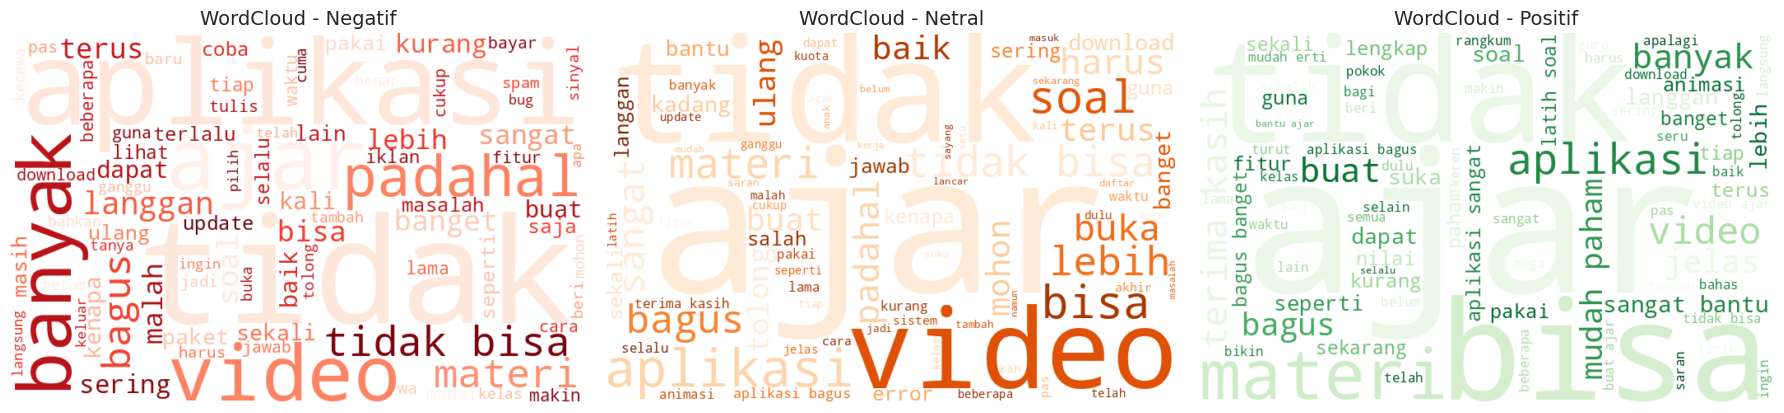

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    teks = " ".join(df.loc[df["label"] == lab, "clean_content"])
    wc = WordCloud(width=700, height=450, background_color="white", colormap="Reds" if lab=="Negatif" else "Oranges" if lab=="Netral" else "Greens",
                   max_words=80, random_state=SEED).generate(teks)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off"); ax.set_title(f"WordCloud - {lab}", fontsize=14)
plt.tight_layout(); plt.show()

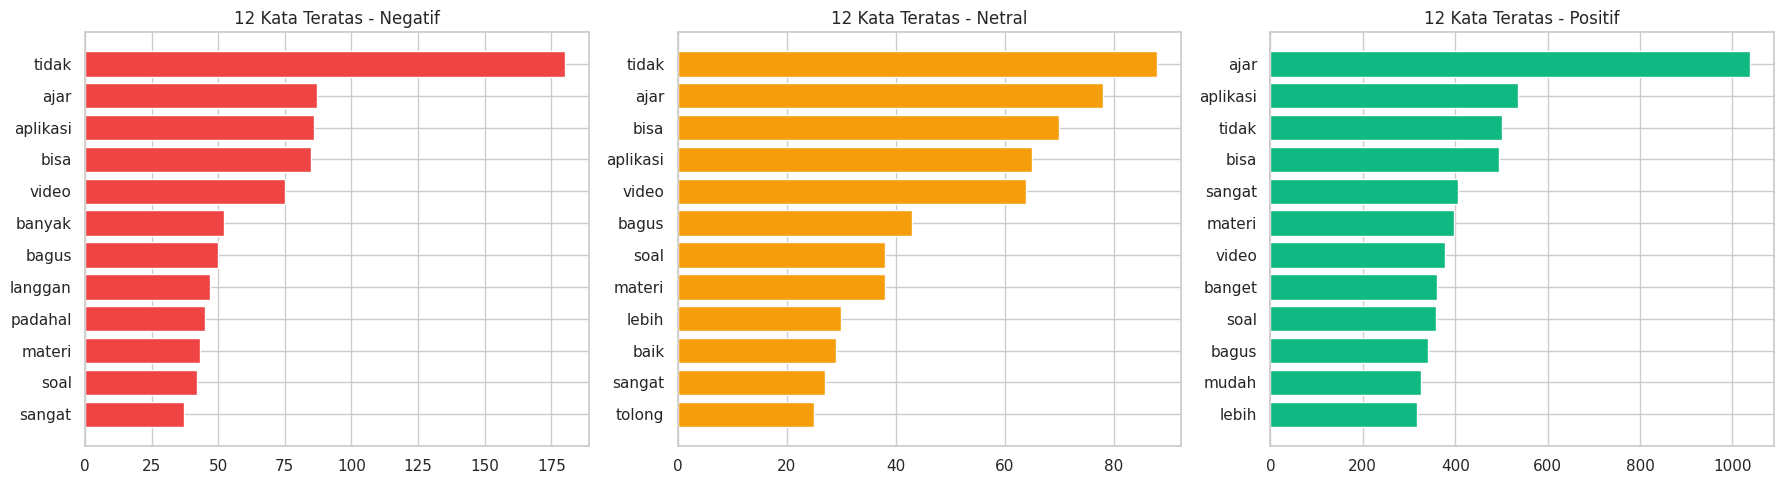

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, lab in zip(axes, ["Negatif", "Netral", "Positif"]):
    top = pd.Series(" ".join(df.loc[df["label"] == lab, "clean_content"]).split()).value_counts().head(12)[::-1]
    ax.barh(top.index, top.values, color=PALETTE[lab]); ax.set_title(f"12 Kata Teratas - {lab}")
plt.tight_layout(); plt.show()

In [19]:
X_train_txt, X_test_txt, y_train, y_test = train_test_split(
    df["clean_content"], df["label"], test_size=0.2, stratify=df["label"], random_state=SEED
)

print(f"Data latih: {len(X_train_txt)} | Data uji: {len(X_test_txt)}")
pd.DataFrame({"Latih": y_train.value_counts(), "Uji": y_test.value_counts()})

Data latih: 799 | Data uji: 200


,Latih,Uji
label,,
Positif,625,156
Negatif,105,27
Netral,69,17


In [25]:
def buat_sampler(y, faktor=1.0):
    min_n = int(pd.Series(y).value_counts().min() * faktor)
    k = min(5, min_n - 1)
    return SMOTE(k_neighbors=k, random_state=SEED) if k >= 1 else RandomOverSampler(random_state=SEED)

N_FOLD = 5
pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB()),
])
param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__max_features": [2000, 5000],
    "tfidf__min_df": [1, 2, 3],
    "nb__alpha": [0.05, 0.1, 0.3, 0.5, 1.0],
}
gs = GridSearchCV(pipe, param_grid, scoring="f1_macro",
                  cv=StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED), n_jobs=-1)
gs.fit(X_train_txt, y_train)

print("Parameter terbaik:", gs.best_params_)
print(f"F1-macro CV terbaik: {gs.best_score_:.4f}")
hasil_grid = (pd.DataFrame(gs.cv_results_)[["param_tfidf__ngram_range","param_tfidf__max_features","param_tfidf__min_df","param_nb__alpha","mean_test_score"]]
             .rename(columns=lambda c: c.replace("param_","")).sort_values("mean_test_score", ascending=False))
hasil_grid.head(10)

Parameter terbaik: {'nb__alpha': 0.5, 'tfidf__max_features': 2000, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)}
F1-macro CV terbaik: 0.5882


,tfidf__ngram_range,tfidf__max_features,tfidf__min_df,nb__alpha,mean_test_score
36,"(1, 1)",2000,1,0.5,0.588248
48,"(1, 1)",2000,1,1.0,0.582289
58,"(1, 1)",5000,3,1.0,0.581286
52,"(1, 1)",2000,3,1.0,0.581286
42,"(1, 1)",5000,1,0.5,0.576957
24,"(1, 1)",2000,1,0.3,0.576649
54,"(1, 1)",5000,1,1.0,0.574576
59,"(1, 2)",5000,3,1.0,0.572542
53,"(1, 2)",2000,3,1.0,0.572542
40,"(1, 1)",2000,3,0.5,0.572448


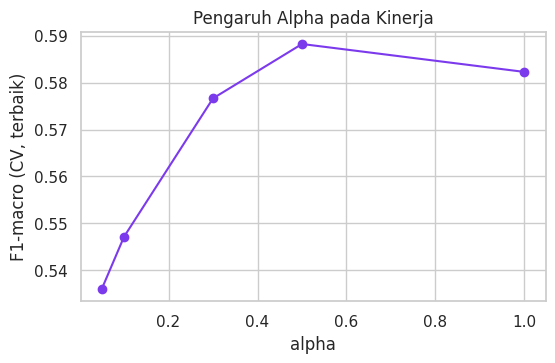

In [26]:
# Pengaruh alpha (Laplace smoothing) terhadap F1-macro
g = hasil_grid.groupby("nb__alpha")["mean_test_score"].max()
plt.figure(figsize=(6, 3.5)); plt.plot(g.index, g.values, marker="o", color="#7C3AED")
plt.xlabel("alpha"); plt.ylabel("F1-macro (CV, terbaik)"); plt.title("Pengaruh Alpha pada Kinerja"); plt.show()

In [27]:
bp = gs.best_params_
vectorizer = TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                             min_df=bp["tfidf__min_df"], sublinear_tf=True)
X_train = vectorizer.fit_transform(X_train_txt)     # fit hanya di data latih
X_test = vectorizer.transform(X_test_txt)
print("Bentuk matriks TF-IDF latih:", X_train.shape)

sampler = buat_sampler(y_train)
X_train_bal, y_train_bal = sampler.fit_resample(X_train, y_train)     # SMOTE hanya pada data latih
print(type(sampler).__name__)
pd.DataFrame({"Sebelum": y_train.value_counts(), "Sesudah": pd.Series(y_train_bal).value_counts()})

Bentuk matriks TF-IDF latih: (799, 2000)
SMOTE


,Sebelum,Sesudah
label,,
Positif,625,625
Negatif,105,625
Netral,69,625


In [28]:
model = MultinomialNB(alpha=bp["nb__alpha"])
model.fit(X_train_bal, y_train_bal)
classes = list(model.classes_)
print(f"Model Multinomial Naive Bayes dilatih (alpha={bp['nb__alpha']}), kelas: {classes}")

Model Multinomial Naive Bayes dilatih (alpha=0.5), kelas: [np.str_('Negatif'), np.str_('Netral'), np.str_('Positif')]


In [29]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)

metrik = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
    "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0),
    "F1-Score (weighted)": f1_score(y_test, y_pred, average="weighted", zero_division=0),
}
tabel_metrik = pd.DataFrame(metrik, index=["Nilai"]).T
display(tabel_metrik.style.format("{:.4f}").background_gradient(cmap="Purples"))

print("\nClassification Report:\n")
print(classification_report(y_test, y_pred, zero_division=0))

,Nilai
Accuracy,0.7700
Precision (macro),0.5010
Recall (macro),0.5478
F1-Score (macro),0.5159
F1-Score (weighted),0.7789



Classification Report:

              precision    recall  f1-score   support

     Negatif       0.44      0.67      0.53        27
      Netral       0.13      0.12      0.12        17
     Positif       0.93      0.86      0.89       156

    accuracy                           0.77       200
   macro avg       0.50      0.55      0.52       200
weighted avg       0.80      0.77      0.78       200



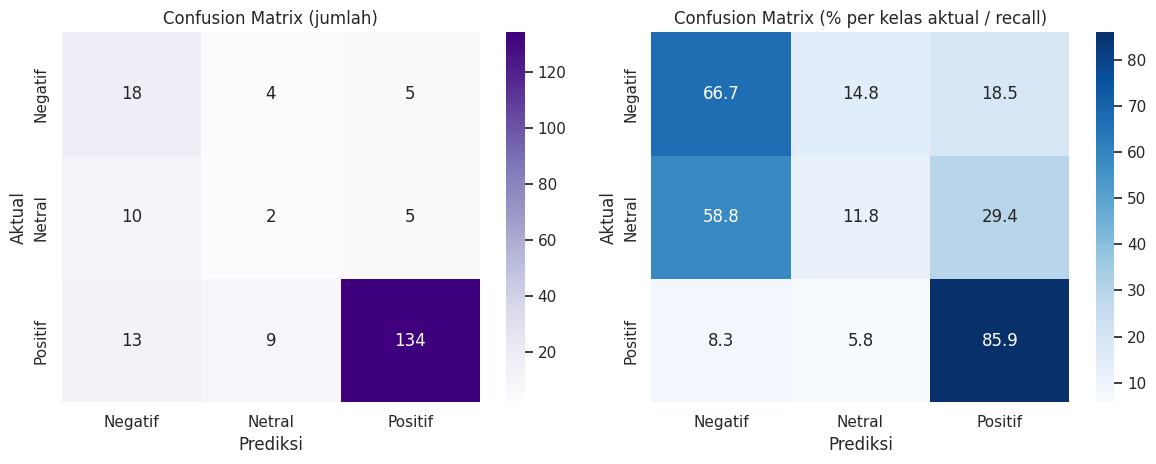

In [30]:
cm = confusion_matrix(y_test, y_pred, labels=classes)
cm_pct = cm / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=classes, yticklabels=classes, ax=ax[0])
ax[0].set(title="Confusion Matrix (jumlah)", xlabel="Prediksi", ylabel="Aktual")
sns.heatmap(cm_pct, annot=True, fmt=".1f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=ax[1])
ax[1].set(title="Confusion Matrix (% per kelas aktual / recall)", xlabel="Prediksi", ylabel="Aktual")
plt.tight_layout(); plt.show()

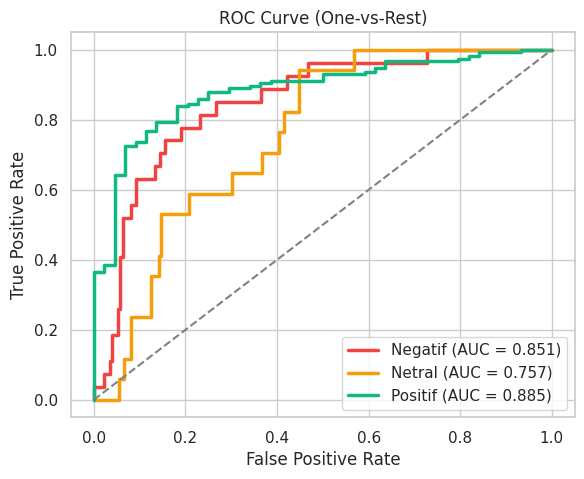

ROC-AUC macro: 0.8310


In [31]:
# ROC Curve One-vs-Rest
Y = label_binarize(y_test, classes=classes)
plt.figure(figsize=(6.5, 5))
aucs = {}
for i, c in enumerate(classes):
    fpr, tpr, _ = roc_curve(Y[:, i], y_prob[:, i])
    aucs[c] = roc_auc_score(Y[:, i], y_prob[:, i])
    plt.plot(fpr, tpr, lw=2.5, color=PALETTE[c], label=f"{c} (AUC = {aucs[c]:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate"); plt.title("ROC Curve (One-vs-Rest)")
plt.legend(loc="lower right"); plt.show()
print(f"ROC-AUC macro: {np.mean(list(aucs.values())):.4f}")

,Fold,Accuracy,F1-macro
0,Fold 1,0.7812,0.5530
1,Fold 2,0.7937,0.5753
2,Fold 3,0.8125,0.6581
3,Fold 4,0.7812,0.5639
4,Fold 5,0.7610,0.5909


Accuracy  : 0.7860 ± 0.0169
F1-macro  : 0.5882 ± 0.0371


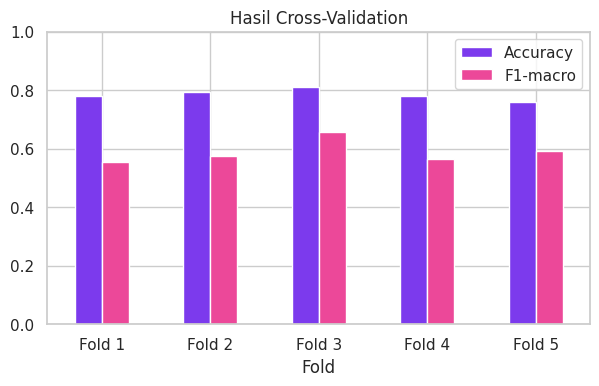

In [32]:
# Cross-Validation pada data latih (TF-IDF + SMOTE dihitung ulang di tiap fold)
best_pipe = ImbPipeline([
    ("tfidf", TfidfVectorizer(ngram_range=bp["tfidf__ngram_range"], max_features=bp["tfidf__max_features"],
                             min_df=bp["tfidf__min_df"], sublinear_tf=True)),
    ("smote", buat_sampler(y_train, faktor=(N_FOLD-1)/N_FOLD)),
    ("nb", MultinomialNB(alpha=bp["nb__alpha"])),
])

skf = StratifiedKFold(N_FOLD, shuffle=True, random_state=SEED)
cv_acc = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="accuracy")
cv_f1 = cross_val_score(best_pipe, X_train_txt, y_train, cv=skf, scoring="f1_macro")

cv_df = pd.DataFrame({"Fold": [f"Fold {i+1}" for i in range(N_FOLD)], "Accuracy": cv_acc, "F1-macro": cv_f1})
display(cv_df.style.format({"Accuracy": "{:.4f}", "F1-macro": "{:.4f}"}))
print(f"Accuracy  : {cv_acc.mean():.4f} ± {cv_acc.std():.4f}")
print(f"F1-macro  : {cv_f1.mean():.4f} ± {cv_f1.std():.4f}")

cv_df.set_index("Fold").plot(kind="bar", figsize=(7, 3.8), color=["#7C3AED", "#EC4899"], rot=0)
plt.ylim(0, 1); plt.title("Hasil Cross-Validation"); plt.show()

In [33]:
# Contoh prediksi yang salah (untuk analisis error)
salah = pd.DataFrame({"ulasan": X_test_txt.values, "aktual": y_test.values, "prediksi": y_pred,
                      "keyakinan": y_prob.max(axis=1)})
salah = salah[salah["aktual"] != salah["prediksi"]].sort_values("keyakinan", ascending=False)
print(f"Jumlah salah prediksi: {len(salah)} dari {len(y_test)}")
salah.head(10)

Jumlah salah prediksi: 46 dari 200


,ulasan,aktual,prediksi,keyakinan
143,turut aplikasi bagus yah lebih suka baca buku ...,Negatif,Positif,0.851859
121,hai benar benar terima kasih sangat bantu paha...,Negatif,Positif,0.845625
166,seluruh sangat baik sangat bantu ajar utama ba...,Positif,Negatif,0.785249
67,kendala akhir akhir tiap pakai aplikasi sering...,Netral,Negatif,0.766803
41,aplikasi keren banget bakal lebih keren misal ...,Positif,Netral,0.758103
58,beberapa kali login nomor orang tua namun teta...,Netral,Negatif,0.757149
168,soal aplikasi no problemakan npln sms lain sua...,Positif,Negatif,0.744116
48,kadang masalah kata server sibuk jaring penuh ...,Positif,Netral,0.741380
29,seluruh bagus bingung batas jumlah perangkat a...,Positif,Negatif,0.739825
152,bagus aplikasi sngt bantu animasi animasi begi...,Netral,Positif,0.687391


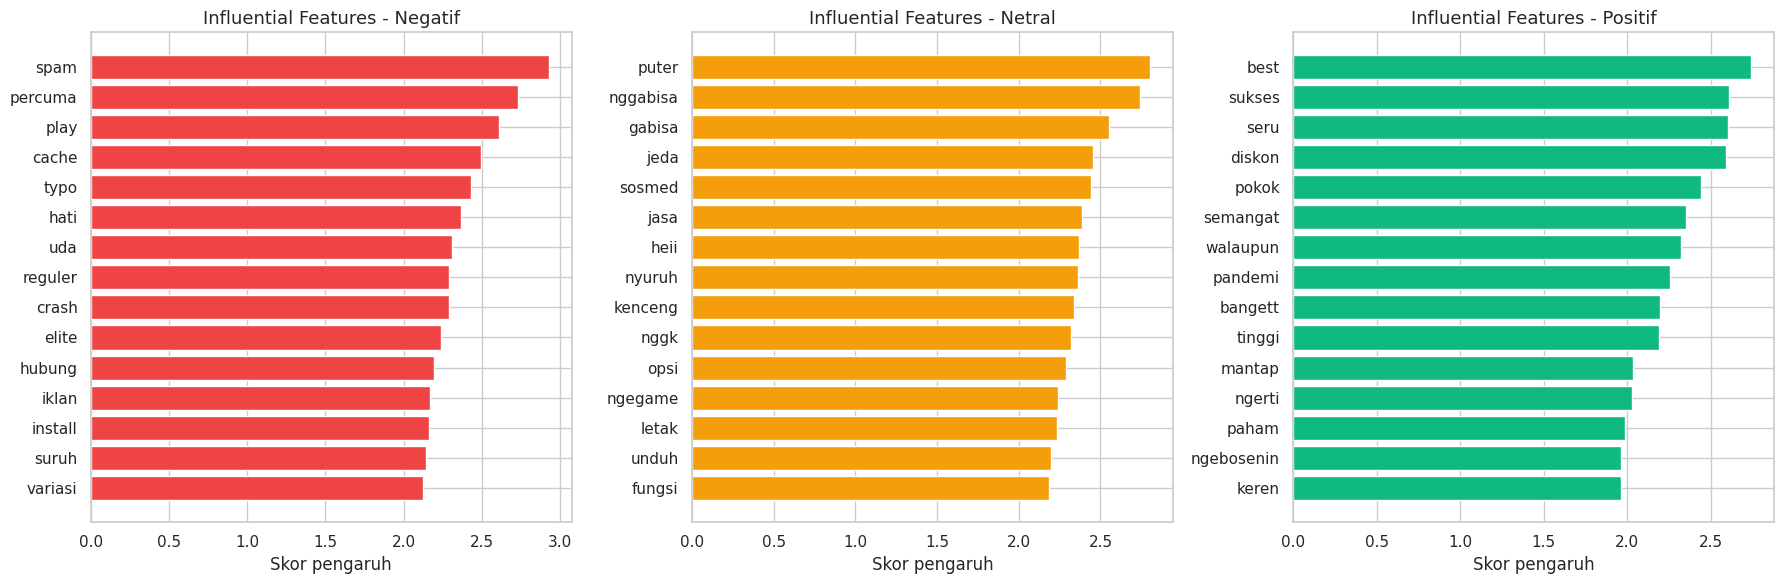

In [34]:
fitur = np.array(vectorizer.get_feature_names_out())
flp = model.feature_log_prob_

def fitur_berpengaruh(top_n=15):
    rows = []
    for i, c in enumerate(classes):
        selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
        for rank, j in enumerate(np.argsort(selisih)[::-1][:top_n]):
            rows.append({"Kelas": c, "Rank": rank, "Fitur": fitur[j], "Skor Pengaruh": selisih[j],
                         "Rasio Odds": np.exp(selisih[j]), "log P(kata|kelas)": flp[i, j]})
    return pd.DataFrame(rows)

inf = fitur_berpengaruh(15)
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, c in zip(axes, classes):
    d = inf[inf["Kelas"] == c].sort_values("Skor Pengaruh")
    ax.barh(d["Fitur"], d["Skor Pengaruh"], color=PALETTE[c]); ax.set_title(f"Influential Features - {c}", fontsize=13)
    ax.set_xlabel("Skor pengaruh")
plt.tight_layout(); plt.show()

In [35]:
display(inf.pivot(index="Rank", columns="Kelas", values="Fitur")[classes])

Kelas,Negatif,Netral,Positif
Rank,,,
0,spam,puter,best
1,percuma,nggabisa,sukses
2,play,gabisa,seru
3,cache,jeda,diskon
4,typo,sosmed,pokok
5,hati,jasa,semangat
6,uda,heii,walaupun
7,reguler,nyuruh,pandemi
8,crash,kenceng,bangett


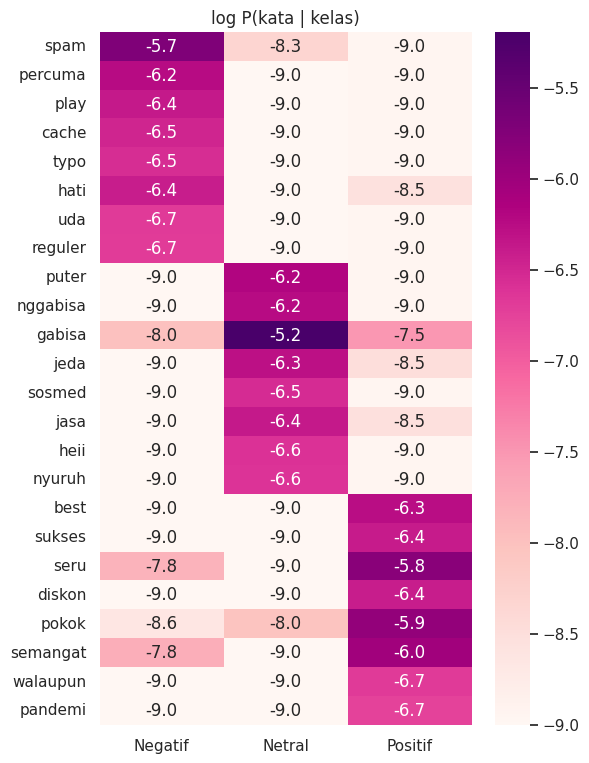

In [36]:
# Heatmap log-probabilitas kata teratas x kelas
pilih = []
for i in range(len(classes)):
    selisih = flp[i] - np.delete(flp, i, axis=0).mean(axis=0)
    pilih += list(np.argsort(selisih)[::-1][:8])
pilih = list(dict.fromkeys(pilih))
hm = pd.DataFrame(flp[:, pilih].T, index=fitur[pilih], columns=classes)
plt.figure(figsize=(6, 9)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="RdPu"); plt.title("log P(kata | kelas)"); plt.show()

,Aspek,Jumlah,Rata-rata Rating,% Negatif,% Netral,% Positif
0,Materi & Soal,638,4.35,9.6,7.2,83.2
1,Mentor / Guru,629,4.48,7.0,6.4,86.6
2,Video & Animasi,402,4.25,11.4,9.0,79.6
3,Teknis & Performa,315,3.63,24.8,14.9,60.3
4,Fitur & Tampilan,266,4.23,12.0,7.5,80.5
5,Harga & Langganan,260,3.83,23.8,8.1,68.1
6,Layanan & Iklan,63,2.78,50.8,11.1,38.1


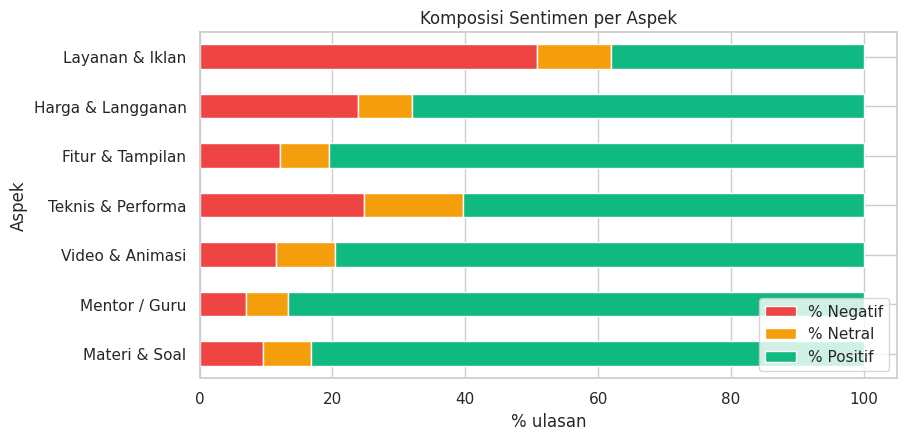

In [37]:
ASPEK = {
    "Mentor / Guru": r"guru|mentor|pengajar|tutor|kakak|penjelasan|menjelaskan",
    "Materi & Soal": r"materi|soal|latihan|rangkuman|pembahasan|kuis|pelajaran|kurikulum|bab",
    "Video & Animasi": r"video|animasi|tayang|nonton|subtitle|suara",
    "Harga & Langganan": r"harga|mahal|langganan|berlangganan|paket|bayar|biaya|promo|diskon|gratis|saldo|refund",
    "Teknis & Performa": r"error|bug|crash|lemot|lambat|loading|download|kuota|login|update|hang|ngelag|tidak bisa|gak bisa|susah",
    "Fitur & Tampilan": r"fitur|tampilan|menu|interface|desain|navigasi|opsi",
    "Layanan & Iklan": r"spam|iklan|telepon|sales|cs|customer|layanan|notifikasi|tawar",
}

low = df["content"].str.lower()
rows = []
for nama, pola in ASPEK.items():
    m = low.str.contains(pola, regex=True); sub = df[m]
    rows.append({"Aspek": nama, "Jumlah": int(m.sum()), "Rata-rata Rating": sub["score"].mean(),
                 "% Negatif": (sub["label"] == "Negatif").mean()*100, "% Netral": (sub["label"] == "Netral").mean()*100,
                 "% Positif": (sub["label"] == "Positif").mean()*100})

asp = pd.DataFrame(rows).sort_values("Jumlah", ascending=False).reset_index(drop=True)
display(asp.style.format({"Rata-rata Rating": "{:.2f}", "% Negatif": "{:.1f}", "% Netral": "{:.1f}", "% Positif": "{:.1f}"}).background_gradient(cmap="Purples"))

asp.set_index("Aspek")[["% Negatif", "% Netral", "% Positif"]].plot(
    kind="barh", stacked=True, figsize=(9, 4.5), color=[PALETTE["Negatif"], PALETTE["Netral"], PALETTE["Positif"]])
plt.xlabel("% ulasan"); plt.title("Komposisi Sentimen per Aspek"); plt.legend(loc="lower right"); plt.show()

In [38]:
def prediksi(teks, top_k=6):
    bersih = bersihkan_teks(teks)
    X = vectorizer.transform([bersih])
    p = model.predict_proba(X)[0]
    pred = classes[p.argmax()]
    kontrib = []
    ref = classes[np.argsort(p)[::-1][1]]
    for j in X.nonzero()[1]:
        kontrib.append((fitur[j], (flp[classes.index(pred), j] - flp[classes.index(ref), j]) * X[0, j]))
    kontrib = sorted(kontrib, key=lambda x: -x[1])[:top_k]
    return pred, dict(zip(classes, p.round(3))), kontrib

for t in ["Aplikasinya bagus banget, materi lengkap dan gurunya jelas!",
          "Sering error, tidak bisa login, kecewa sekali",
          "Lumayan lah tapi masih banyak yang perlu diperbaiki"]:
    pred, prob, kontrib = prediksi(t)
    print(f"\n✍️ {t}\n-> {pred} {prob}\n   kata pendorong: {[k for k, _ in kontrib]}")


✍️ Aplikasinya bagus banget, materi lengkap dan gurunya jelas!
-> Positif {np.str_('Negatif'): np.float64(0.063), np.str_('Netral'): np.float64(0.181), np.str_('Positif'): np.float64(0.755)}
   kata pendorong: ['jelas', 'guru', 'banget', 'lengkap', 'materi', 'aplikasi']

✍️ Sering error, tidak bisa login, kecewa sekali
-> Netral {np.str_('Negatif'): np.float64(0.431), np.str_('Netral'): np.float64(0.535), np.str_('Positif'): np.float64(0.034)}
   kata pendorong: ['error', 'login', 'bisa', 'tidak', 'sekali', 'sering']

✍️ Lumayan lah tapi masih banyak yang perlu diperbaiki
-> Positif {np.str_('Negatif'): np.float64(0.18), np.str_('Netral'): np.float64(0.41), np.str_('Positif'): np.float64(0.41)}
   kata pendorong: ['lumayan', 'banyak', 'perlu', 'baik', 'masih']


In [41]:
import joblib
joblib.dump({"vectorizer": vectorizer, "model": model, "classes": classes, "best_params": bp,
             "metrics": metrik, "cm": cm}, "model_nb_sentimen.joblib")
df.to_csv("data_bersih_berlabel.csv", index=False)
print("Tersimpan: model_nb_sentimen.joblib, data_bersih_berlabel.csv, stem_cache.json")

Tersimpan: model_nb_sentimen.joblib, data_bersih_berlabel.csv, stem_cache.json
